# 06 · Feature importance — tables and plots

This notebook reads the results of the two computing notebooks of step 06 (`06-importance-cpu`, `06-importance-gpu`) and makes the tables and plots of the report. Nothing is trained or explained here. **Runtime: CPU**, a few minutes.

**What each measure says** (the formulas are in the computing notebooks):
- **permutation importance**: the drop of the test PR-AUC when a column, or a whole family, is shuffled within each time step and the model is not retrained. Same definition for every model: *how much does the model rely on it?*
- **attributions** $\phi$ (SHAP for LogReg, RF and XGBoost; Integrated Gradients for MLP and GNNs): how much a column pushes each transaction towards "illicit", with a direction. Their scale depends on the model (log-odds, probability, logit): between models compare **shares**, not values;
- **density** of a family = its share / its share of columns: above 1, the family weighs more than its number of columns;
- **share of the neighbours** (GNNs): the part of the attribution that comes from the features of the neighbours, not of the transaction itself (0 for the MLP by construction);
- **GNNExplainer**: which edges of the neighbourhood a GNN needs to keep its prediction.

Importances are reported as **mean ± standard deviation over the 3 seeds**, never the best seed. Plots of a single run (beeswarm, dependence, waterfall, GNNExplainer) use seed 0, fixed in advance. Where a plot needs one GNN for a menu, it is the GNN with the best **validation** PR-AUC (mean over seeds), as in step 05; if the best GNN on the test is another one, its plot goes to the appendix.

**Outputs:** tables in `06-feature-importance/` (`importance.csv`, `importance_summary.csv`, `stability.csv`, `gnnexplainer_summary.csv`, `gnnexplainer_stability.csv`, `gnnexplainer_features.csv`) and plots `plots/06_*.png`.

## 0. Setup

In [1]:
# Connect Google Drive: every input and output of the project lives in DATA_PATH.
from pathlib import Path
from google.colab import drive

drive.mount('/content/drive')

DATA_PATH = Path('/content/drive/MyDrive/UNIVERSITA/block-crypto/data')
INPUT_DIR = DATA_PATH / '02-feature-menus'          # output of step 02
RUNS_DIR = DATA_PATH / '04-final-runs'              # output of step 04
OUT_DIR = DATA_PATH / '06-feature-importance'       # output of step 06 (and the tables of this notebook)
PLOT_DIR = DATA_PATH / 'plots'                      # every plot of the project

Mounted at /content/drive


In [2]:
import itertools
import json
import os

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from PIL import Image
from scipy.stats import spearmanr

FORCE_RECOMPUTE = False   # True = write again the tables and plots that are already on Drive
ALLOW_MISSING = False     # True = make the plots with the triples that exist (for a partial run)
REFERENCE_SEED = 0        # the run of the single-run plots (fixed before seeing the results)
TOP_N = 15                # columns in the ranking plots
SWARM_TOP = 12            # columns in the beeswarm plots
PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
# Colours of the report (as in step 05). Classes: red, blue, light grey. Two or three series: the first categorical
# slots. Magnitudes: one blue ramp, light = low, calibrated on the extremes of each map. Single series: dark grey.
# Directions (waterfall): red = towards illicit, blue = towards licit, the two classes' colours.
SURFACE, INK, INK_2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
CLASS_COLOR = {'illicit': '#e34948', 'licit': '#2a78d6', 'unknown': '#d4d3cc'}
CLASS_NAMES = ['illicit', 'licit', 'unknown']
NEUTRAL = '#52514e'
SERIES = ['#2a78d6', '#eb6834', '#1baf7a']
BLUE_RAMP = ['#cde2fb', '#b7d3f6', '#9ec5f4', '#86b6ef', '#6da7ec', '#5598e7', '#3987e5', '#2a78d6', '#256abf',
             '#1c5cab', '#184f95', '#104281', '#0d366b']
BLUE_CMAP = LinearSegmentedColormap.from_list('blue', BLUE_RAMP)
MODELS = ['logreg', 'rf', 'xgb', 'mlp', 'sage', 'gatv2', 'cheb', 'gin']
GNNS = ['sage', 'gatv2', 'cheb']
MODEL_NAME = {'logreg': 'LogReg', 'rf': 'Random Forest', 'xgb': 'XGBoost', 'mlp': 'MLP', 'sage': 'GraphSAGE',
              'gatv2': 'GATv2', 'cheb': 'ChebNet', 'gin': 'GIN'}
ATTR_METHOD = {'logreg': 'linear_shap', 'rf': 'tree_shap', 'xgb': 'tree_shap', 'mlp': 'integrated_gradients',
               'sage': 'integrated_gradients', 'gatv2': 'integrated_gradients', 'cheb': 'integrated_gradients',
               'gin': 'integrated_gradients'}
ATTR_LABEL = {'linear_shap': 'SHAP, log-odds', 'tree_shap': 'TreeSHAP', 'integrated_gradients': 'Integrated Gradients, logit'}
FAMILIES = ['LF', 'AF', 'A', 'B', 'C', 'D']
FAMILY_NAME = {'LF': 'LF (local)', 'AF': 'AF (aggregate)', 'A': 'A (degrees, counts)', 'B': 'B (centralities)',
               'C': 'C (motifs, curvature)', 'D': 'D (economic)'}
FEATURE_MENUS = ['local', 'graph', 'econ', 'local_agg', 'transparent', 'local_agg_graph']
MULTI_FAMILY = ['local_agg', 'graph', 'transparent', 'local_agg_graph']
STRATA = ['TP', 'FN', 'FP', 'TN']

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'text.color': INK, 'axes.labelcolor': INK_2, 'xtick.color': INK_2, 'ytick.color': INK_2,
    'axes.edgecolor': AXIS, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
})
MAX_PIXELS, MAX_KB = (1200, 800), 200


def atomic(path, write):
    tmp = path.with_name(path.name + '.tmp')
    write(tmp)
    os.replace(tmp, path)


def save_table(df, name, show=True):
    """Show a table and write it to OUT_DIR (unless it is already there)."""
    if show:
        display(df)
    path = OUT_DIR / name
    if path.exists() and not FORCE_RECOMPUTE:
        print(f'{name} is already on Drive: not overwritten.')
    else:
        atomic(path, lambda tmp: df.to_csv(tmp, index=False, float_format='%.6g'))
        print(f'{name} written ({len(df):,} rows).')


def save_png(fig, name):
    """Show a figure and save it at 100 dpi: at most 1200 x 800 pixels and 200 KB
    (a 256-colour PNG if the full-colour one is too big). An existing plot is not overwritten."""
    width, height = fig.get_size_inches() * 100
    assert width <= MAX_PIXELS[0] + 0.5 and height <= MAX_PIXELS[1] + 0.5, 'figure too large'
    path = PLOT_DIR / name
    if path.exists() and not FORCE_RECOMPUTE:
        plt.show()
        plt.close(fig)
        print(f'{name} is already on Drive: not overwritten.')
        return
    tmp = path.with_name(path.name + '.tmp')
    fig.savefig(tmp, dpi=100, format='png')
    plt.show()
    plt.close(fig)
    if tmp.stat().st_size > MAX_KB * 1000:
        with Image.open(tmp) as image:
            small = image.convert('RGB').quantize(256)
        small.save(tmp, format='PNG', optimize=True)
    size = tmp.stat().st_size / 1000
    assert size <= MAX_KB, f'{name}: {size:.0f} KB'
    os.replace(tmp, path)
    print(f'{name} written ({size:.0f} KB).')


def titles(fig, title, subtitle, top=0.97):
    fig.text(0.02, top, title, fontsize=13, weight='bold', ha='left', va='top')
    fig.text(0.02, top - 0.045 * 8 / fig.get_size_inches()[1], subtitle, fontsize=9, color=INK_2,
             ha='left', va='top', linespacing=1.4)


def text_color_on(rgba):
    r, g, b = rgba[:3]
    return 'white' if 0.2126 * r + 0.7152 * g + 0.0722 * b < 0.5 else INK


def light_grid(ax, axis='y'):
    ax.grid(axis=axis, color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)


def empty_panel(ax, text):
    ax.axis('off')
    ax.text(0.5, 0.5, text, ha='center', va='center', color=MUTED, transform=ax.transAxes)


def heatmap(ax, values, row_labels, col_labels, texts, norm=None):
    """One hue, calibrated on the extremes of the map (lightest = lowest, darkest = highest); NaN cells empty."""
    finite = values[np.isfinite(values)]
    norm = norm or Normalize(finite.min() if len(finite) else 0, finite.max() if len(finite) else 1, clip=True)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            if not np.isfinite(values[i, j]):
                ax.text(j + 0.5, i + 0.5, '–', ha='center', va='center', color=MUTED)
                continue
            color = BLUE_CMAP(norm(values[i, j]))
            ax.add_patch(Rectangle((j + 0.03, i + 0.04), 0.94, 0.92, facecolor=color, edgecolor='none'))
            ax.text(j + 0.5, i + 0.5, texts[i][j], ha='center', va='center', fontsize=8, color=text_color_on(color),
                    linespacing=1.25)
    ax.set_xlim(0, values.shape[1])
    ax.set_ylim(values.shape[0], 0)
    ax.set_xticks(np.arange(values.shape[1]) + 0.5, col_labels)
    ax.set_yticks(np.arange(values.shape[0]) + 0.5, row_labels)
    ax.tick_params(length=0)
    for side in ['left', 'bottom']:
        ax.spines[side].set_visible(False)
    return norm

## 1. Load the results

The notebook stops if a triple or a GNNExplainer pair is missing (unless `ALLOW_MISSING = True`), and prints the checks of the two computing notebooks: every reloaded model gave back its saved scores, attributions add up to the output of the model, subgraphs give the same logits as the whole graph.

In [4]:
config = json.loads((INPUT_DIR / 'config.json').read_text(encoding='utf-8'))
SEEDS = config['final_runs']['seeds']
PAIRS = [tuple(p) for p in config['pairs']]
PAIR_SET = set(PAIRS)
FAM = {col: f for f in FAMILIES for col in config['columns']['families'][f]['kept']}
N_COLUMNS = {m: len(spec['columns']) for m, spec in config['menus'].items()}
N_TEST = config['split']['test']['eval_rows']


def triple_id(menu, model, seed):
    return f'{menu}__{model}__seed{seed}'


def parse(stem):
    menu, model, seed = stem.split('__')
    return menu, model, int(seed.replace('seed', ''))


RECORDS = {}
for path in (RUNS_DIR / 'summary').glob('*.json'):
    r = json.loads(path.read_text(encoding='utf-8'))
    RECORDS[(r['menu'], r['model'], r['seed'])] = r
DONE = {parse(p.stem): json.loads(p.read_text(encoding='utf-8')) for p in (OUT_DIR / 'done').glob('*.json')}
expected = [(m, mo, s) for m, mo in PAIRS for s in SEEDS]
missing = [triple_id(*t) for t in expected if t not in DONE]
gx_expected = [f'{m}__{mo}' for m, mo in PAIRS if mo in GNNS + ['gin']]
gx_missing = [p for p in gx_expected if not (OUT_DIR / 'gnnexplainer' / f'{p}.json').exists()]
print(f'Triples explained: {len(expected) - len(missing)} of {len(expected)}; GNNExplainer pairs: '
      f'{len(gx_expected) - len(gx_missing)} of {len(gx_expected)}.')
if missing or gx_missing:
    message = f'missing: {missing[:4]}{"..." if len(missing) > 4 else ""} {gx_missing[:4]}'
    assert ALLOW_MISSING, message + ' -> run the computing notebooks again, or set ALLOW_MISSING = True'
    print('ALLOW_MISSING: the plots use what exists.', message)
assert len({d['shared_code_version'] for d in DONE.values()}) <= 1, 'triples explained with different shared code'

SAMPLE = pd.read_csv(OUT_DIR / 'explain_sample.csv')
WEIGHT = SAMPLE.set_index('row')['weight']
CHECKS = pd.read_csv(OUT_DIR / 'checks.csv')
display(CHECKS.groupby('check').agg(triples=('triple', 'count'), largest=('value', 'max'), limit=('limit', 'first'),
                                    all_ok=('ok', 'all')))
assert CHECKS['ok'].all(), 'a check failed'


def read_folder(folder, suffix):
    tables = []
    for path in sorted((OUT_DIR / folder).glob(f'*{suffix}')):
        menu, model, seed = parse(path.name[:-len(suffix)])
        tables.append(pd.read_csv(path).assign(menu=menu, model=model, seed=seed))
    return pd.concat(tables, ignore_index=True) if tables else pd.DataFrame()


PERM = read_folder('permutation', '.csv')
ATTR = read_folder('shap_summary', '.csv')
print(f'Permutation rows: {len(PERM):,}; attribution rows: {len(ATTR):,}.')

columns_needed = sorted(set(config['menus']['transparent']['columns']) | set(config['menus']['graph']['columns'])
                        | set(config['menus']['econ']['columns']))
RAW = pd.read_parquet(INPUT_DIR / 'dataset.parquet', columns=columns_needed + ['y'])
Y_ALL = RAW['y'].to_numpy(dtype=np.float64, na_value=np.nan)
CLASS_OF = np.where(np.isnan(Y_ALL), 2, np.where(Y_ALL == 1, 0, 1))      # 0 illicit, 1 licit, 2 unknown


def chosen_gnn(menu, split='val'):
    """The GNN with the best mean PR-AUC over the seeds on `split` (validation: the choice; test: for the appendix)."""
    candidates = [g for g in GNNS if all((menu, g, s) in RECORDS for s in SEEDS)
                  and (menu, g, REFERENCE_SEED) in DONE]
    if not candidates:
        return None
    return max(candidates, key=lambda g: np.mean([RECORDS[(menu, g, s)]['metrics']['by_split'][split]['average_precision']
                                                  for s in SEEDS]))


CHOSEN = {menu: chosen_gnn(menu) for menu in FEATURE_MENUS}
TEST_BEST = {menu: chosen_gnn(menu, 'test') for menu in FEATURE_MENUS}
print('GNN chosen on validation, per menu:', CHOSEN)
print('Best GNN on the test (for comparison only):', TEST_BEST)

Triples explained: 132 of 132; GNNExplainer pairs: 20 of 20.


,triples,largest,limit,all_ok
check,,,,
Integrated Gradients: 95th percentile of the completeness error,18,5.294282e-01,NaN,True
Integrated Gradients: median completeness error,36,3.868422e-02,5.000000e-02,True
TreeSHAP: base + sum of phi = margin,18,1.430511e-05,1.000000e-03,True
TreeSHAP: base + sum of phi = probability,18,4.213976e-08,1.000000e-04,True
linear SHAP: base + sum of phi = logit,18,2.273737e-13,1.000000e-06,True
permutation: scores restored,126,3.330669e-16,1.000000e-09,True
reload: largest score difference,132,6.309925e-07,1.000000e-12,True
reload: test PR-AUC difference,78,3.744038e-06,1.000000e-04,True
subgraph: largest logit difference from the whole graph,18,7.247925e-05,1.000000e-03,True


Permutation rows: 11,361; attribution rows: 7,995.
GNN chosen on validation, per menu: {'local': 'sage', 'graph': 'sage', 'econ': 'sage', 'local_agg': 'sage', 'transparent': 'gatv2', 'local_agg_graph': 'sage'}
Best GNN on the test (for comparison only): {'local': 'gatv2', 'graph': 'gatv2', 'econ': 'gatv2', 'local_agg': 'sage', 'transparent': 'cheb', 'local_agg_graph': 'gatv2'}


## 2. Tables

- **`importance.csv`** — everything in long form, one row per triple, method, data (test, validation, explain sample, train for the internal importances of step 04), level (column, family, menu), name and measure. The measures: `ap_drop`, `roc_drop` and their standard deviations over the shuffles, `ap_drop_share` and `ap_drop_density` (share of the positive drops and share / share of columns) for the permutation; `mean_abs`, `mean_abs_illicit`, `mean`, `share`, `density`, `direction`, `neighbour_share` for the attributions; the coefficient, the mean decrease in impurity or the gain, and their absolute value (`abs`), for the internal importances.
- **`importance_summary.csv`** — mean and standard deviation over the seeds, and the rank of each column (1 = most important) within its triple's ranking.
- **`stability.csv`** — agreement of the rankings of the columns: between seeds (same model and method), between methods (permutation against attributions) and between models (same menu, permutation). Spearman correlation and overlap of the top $k$ columns, with $k = \min(10, \lfloor n/2\rfloor)$ for a menu of $n$ columns.

In [5]:
ID = ['menu', 'model', 'seed', 'method', 'data', 'level', 'name', 'family', 'n_columns']
parts = []
if len(PERM):
    perm = PERM.assign(method='permutation')
    positive = perm['ap_drop'].clip(lower=0)
    totals = positive.groupby([perm['menu'], perm['model'], perm['seed'], perm['data'], perm['level']]).transform('sum')
    perm['ap_drop_share'] = np.where(totals > 0, positive / totals.where(totals > 0, 1), np.nan)
    perm['ap_drop_density'] = perm['ap_drop_share'] / (perm['n_columns'] / perm['menu'].map(N_COLUMNS))
    parts.append(perm.melt(ID, ['ap_drop', 'ap_drop_std', 'roc_drop', 'roc_drop_std', 'ap_drop_share', 'ap_drop_density'],
                           var_name='measure'))
if len(ATTR):
    attr = ATTR.assign(data=np.where(ATTR['rows'] == N_TEST, 'test', 'explain sample'))
    measures = [c for c in ['mean_abs', 'mean_abs_illicit', 'mean', 'share', 'density', 'direction', 'neighbour_share']
                if c in attr.columns]
    parts.append(attr.melt(ID, measures, var_name='measure').dropna(subset=['value']))
internal = []
for (menu, model, seed), r in RECORDS.items():
    if 'importances' in r['files'] and (menu, model, seed) in DONE:
        t = pd.read_csv(RUNS_DIR / r['files']['importances'])
        base = dict(menu=menu, model=model, seed=seed, method='internal', data='train', level='column', n_columns=1)
        internal.append(pd.DataFrame({**base, 'name': t['feature'], 'family': t['feature'].map(FAM),
                                      'measure': t['importance_type'], 'value': t['value']}))
        internal.append(pd.DataFrame({**base, 'name': t['feature'], 'family': t['feature'].map(FAM),
                                      'measure': 'abs', 'value': t['value'].abs()}))
parts += internal
IMPORTANCE = pd.concat(parts, ignore_index=True)
save_table(IMPORTANCE, 'importance.csv', show=False)

SUMMARY = (IMPORTANCE.groupby([c for c in ID if c != 'seed'] + ['measure'])['value']
           .agg(mean='mean', std='std', seeds='count').reset_index())
SUMMARY['rank'] = SUMMARY.groupby(['menu', 'model', 'method', 'data', 'level', 'measure'])['mean'].rank(
    ascending=False, method='first')
save_table(SUMMARY, 'importance_summary.csv', show=False)


def summary(menu, model, method, measure, level='column', data=None, stat='mean'):
    """Mean (or std) over the seeds of one measure, indexed by the name of the column or family."""
    s = SUMMARY[(SUMMARY['menu'] == menu) & (SUMMARY['model'] == model) & (SUMMARY['method'] == method)
                & (SUMMARY['level'] == level) & (SUMMARY['measure'] == measure)]
    if data is not None:
        s = s[s['data'] == data]
    return s.set_index('name')[stat]


def per_seed(menu, model, method, measure, level='column', data=None):
    s = IMPORTANCE[(IMPORTANCE['menu'] == menu) & (IMPORTANCE['model'] == model) & (IMPORTANCE['method'] == method)
                   & (IMPORTANCE['level'] == level) & (IMPORTANCE['measure'] == measure)]
    if data is not None:
        s = s[s['data'] == data]
    return {seed: g.set_index('name')['value'] for seed, g in s.groupby('seed')}


def agreement(a, b, k):
    common = a.index.intersection(b.index)
    if len(common) < 3:
        return np.nan, np.nan
    a, b = a[common], b[common]
    rho = spearmanr(a, b).correlation
    top = lambda s: set(s.sort_values(ascending=False).index[:k])
    return float(rho), len(top(a) & top(b)) / k


rows = []
for menu in FEATURE_MENUS:
    k = min(10, N_COLUMNS[menu] // 2)
    models = [m for m in MODELS if (menu, m) in PAIR_SET]
    for model in models:
        for method, measure, data in [('permutation', 'ap_drop', 'test'), (ATTR_METHOD[model], 'mean_abs', None)]:
            seeds = per_seed(menu, model, method, measure, data=data)
            pairs = [agreement(seeds[a], seeds[b], k) for a, b in itertools.combinations(sorted(seeds), 2)]
            if pairs:
                rows.append({'kind': 'between seeds', 'menu': menu, 'model': model, 'method': method, 'with': 'other seeds',
                             'spearman': np.nanmean([p[0] for p in pairs]), 'top_k_overlap': np.nanmean([p[1] for p in pairs]),
                             'k': k, 'comparisons': len(pairs)})
        a = summary(menu, model, 'permutation', 'ap_drop', data='test')
        b = summary(menu, model, ATTR_METHOD[model], 'mean_abs')
        if len(a) and len(b):
            rho, overlap = agreement(a, b, k)
            rows.append({'kind': 'between methods', 'menu': menu, 'model': model, 'method': 'permutation',
                         'with': ATTR_METHOD[model], 'spearman': rho, 'top_k_overlap': overlap, 'k': k, 'comparisons': 1})
    for a_model, b_model in itertools.combinations(models, 2):
        a = summary(menu, a_model, 'permutation', 'ap_drop', data='test')
        b = summary(menu, b_model, 'permutation', 'ap_drop', data='test')
        if len(a) and len(b):
            rho, overlap = agreement(a, b, k)
            rows.append({'kind': 'between models', 'menu': menu, 'model': a_model, 'method': 'permutation',
                         'with': b_model, 'spearman': rho, 'top_k_overlap': overlap, 'k': k, 'comparisons': 1})
STABILITY = pd.DataFrame(rows)
save_table(STABILITY.round(4), 'stability.csv', show=False)
display(STABILITY.groupby(['kind', 'method'])[['spearman', 'top_k_overlap']].mean().round(3))

importance.csv written (126,614 rows).
importance_summary.csv written (49,633 rows).
stability.csv written (234 rows).


spearman  top_k_overlap
kind            method                                       
between methods permutation              0.375          0.511
between models  permutation              0.328          0.495
between seeds   integrated_gradients     0.862          0.817
                linear_shap              1.000          1.000
                permutation              0.777          0.788
                tree_shap                0.953          0.900

In [6]:
# GNNExplainer: mean mask of the edges by stratum, distance (1, 2, 3+) and class of the neighbour; stability; columns.
def read_pairs(suffix, reader=pd.read_csv):
    tables = [reader(p).assign(pair=p.name[:-len(suffix)]) for p in sorted((OUT_DIR / 'gnnexplainer').glob(f'*{suffix}'))]
    return pd.concat(tables, ignore_index=True) if tables else pd.DataFrame()


BY_DISTANCE = read_pairs('__by_distance.csv')
if len(BY_DISTANCE):
    BY_DISTANCE['bucket'] = np.where(BY_DISTANCE['distance'] >= 3, '3+', BY_DISTANCE['distance'].astype(str))
    BY_DISTANCE['weighted'] = BY_DISTANCE['mean'] * BY_DISTANCE['size']
    per_node = BY_DISTANCE.groupby(['pair', 'target_row', 'stratum', 'core', 'bucket', 'neighbour_class'])[
        ['weighted', 'size']].sum().reset_index()
    per_node['mask'] = per_node['weighted'] / per_node['size']
    GX_SUMMARY = (per_node.groupby(['pair', 'stratum', 'bucket', 'neighbour_class'])
                  .agg(mean_mask=('mask', 'mean'), nodes=('mask', 'count'), edges=('size', 'sum')).reset_index())
    GX_SUMMARY['neighbour_class'] = GX_SUMMARY['neighbour_class'].map(dict(enumerate(CLASS_NAMES)))
    save_table(GX_SUMMARY.round(5), 'gnnexplainer_summary.csv', show=False)
GX_STABILITY = read_pairs('__stability.csv')
if len(GX_STABILITY):
    save_table(GX_STABILITY.round(4), 'gnnexplainer_stability.csv', show=False)
    display(GX_STABILITY.groupby('variant')[['spearman', 'top10_overlap']].agg(['mean', 'std']).round(3))
GX_FEATURES = read_pairs('__features.csv')
if len(GX_FEATURES):
    table = GX_FEATURES.groupby(['pair', 'stratum', 'family', 'feature'])['mask'].mean().reset_index()
    save_table(table.round(5), 'gnnexplainer_features.csv', show=False)

gnnexplainer_summary.csv written (631 rows).
gnnexplainer_stability.csv written (1,200 rows).


spearman        top10_overlap       
                     mean    std          mean    std
variant                                              
explainer seed 1    0.568  0.330         0.740  0.229
model seed 1        0.621  0.317         0.520  0.335
model seed 2        0.613  0.319         0.516  0.350

gnnexplainer_features.csv written (6,156 rows).


## 3. Plot 1 — which families each model relies on (`06_family_heatmap.png`)

For the two menus that mix the most families, `local_agg_graph` (LF, AF, A, B, C) and `transparent` (A, B, C, D): rows = families, columns = models. In each cell, the drop of test PR-AUC when the whole family is shuffled (permutation importance, mean over the 3 seeds) and, below it, its **density** (× 1.0 = the family weighs as much as its share of columns). One hue per map, calibrated on its extremes: lightest = the lowest drop, darkest = the highest.

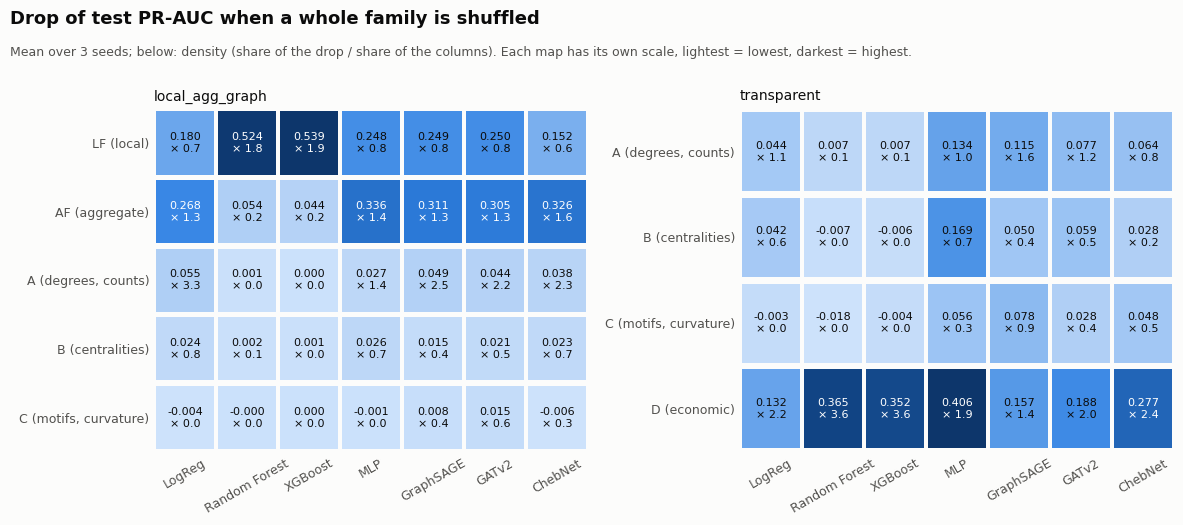

06_family_heatmap.png written (117 KB).


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), gridspec_kw={'width_ratios': [1, 1]})
fig.subplots_adjust(left=0.14, right=0.99, top=0.78, bottom=0.12, wspace=0.35)
for ax, menu in zip(axes, ['local_agg_graph', 'transparent']):
    models = [m for m in MODELS if (menu, m) in PAIR_SET]
    families = [f for f in FAMILIES if any(FAM[c] == f for c in config['menus'][menu]['columns'])]
    values = np.full((len(families), len(models)), np.nan)
    texts = [[''] * len(models) for _ in families]
    for j, model in enumerate(models):
        drop = summary(menu, model, 'permutation', 'ap_drop', level='family', data='test')
        density = summary(menu, model, 'permutation', 'ap_drop_density', level='family', data='test')
        for i, f in enumerate(families):
            if f in drop.index:
                values[i, j] = drop[f]
                texts[i][j] = f'{drop[f]:.3f}\n× {density.get(f, np.nan):.1f}'
    if np.isfinite(values).any():
        heatmap(ax, values, [FAMILY_NAME[f] for f in families], [MODEL_NAME[m] for m in models], texts)
        ax.tick_params(axis='x', labelrotation=30)
        ax.set_title(menu, fontsize=10, loc='left')
    else:
        empty_panel(ax, f'{menu}: not available')
titles(fig, 'Drop of test PR-AUC when a whole family is shuffled',
       'Mean over 3 seeds; below: density (share of the drop / share of the columns). Each map has its own scale, '
       'lightest = lowest, darkest = highest.')
save_png(fig, '06_family_heatmap.png')

## 4. Plot 2 — the most important transparent features, model by model (`06_top_features_transparent.png`)

Menu `transparent` (33 named columns): for each model, the 15 columns with the largest drop of test PR-AUC when shuffled (permutation importance, the same definition for every model), mean over the 3 seeds with the standard deviation. The family of each column is in brackets.

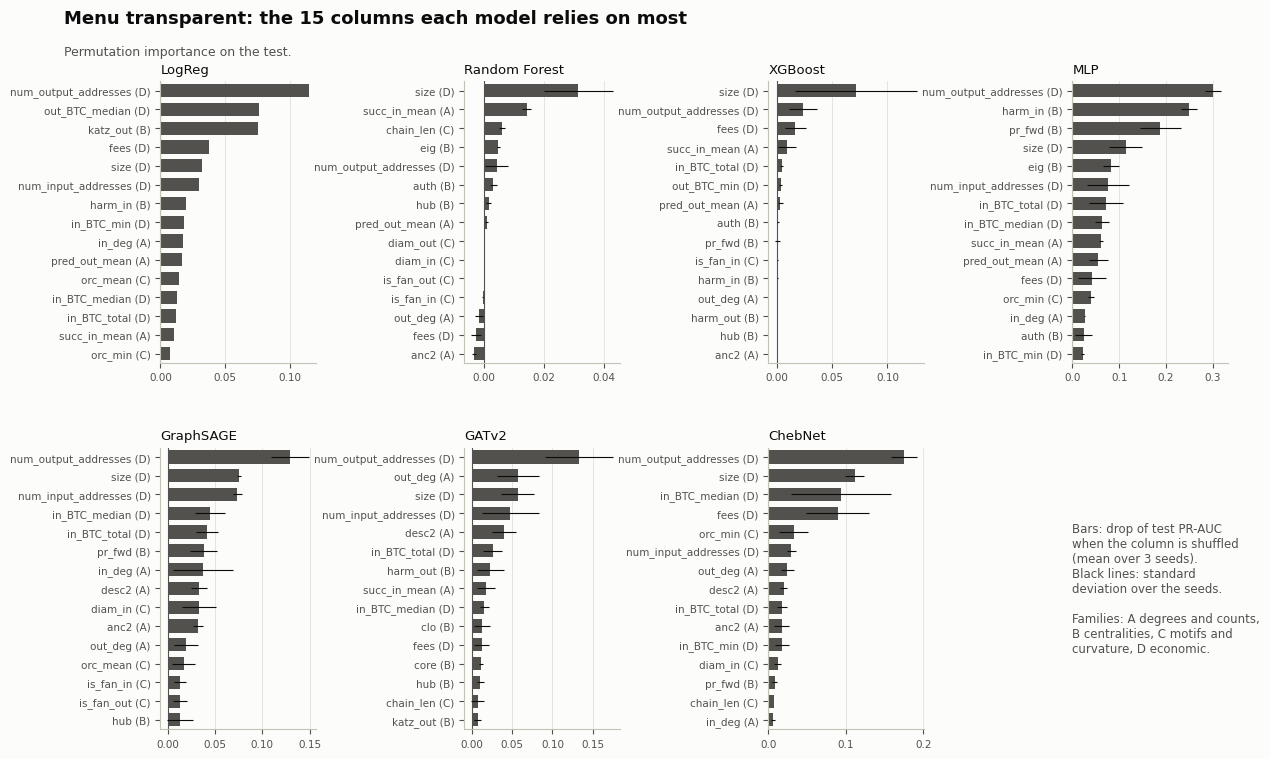

06_top_features_transparent.png written (154 KB).


In [8]:
models = [m for m in MODELS if ('transparent', m) in PAIR_SET]
fig, axes = plt.subplots(2, 4, figsize=(12, 8))
fig.subplots_adjust(left=0.1, right=0.99, top=0.88, bottom=0.07, wspace=0.95, hspace=0.3)
for ax, model in zip(axes.flat, models):
    mean = summary('transparent', model, 'permutation', 'ap_drop', data='test')
    std = summary('transparent', model, 'permutation', 'ap_drop', data='test', stat='std')
    if not len(mean):
        empty_panel(ax, f'{MODEL_NAME[model]}: not available')
        continue
    top = mean.sort_values(ascending=False).index[:TOP_N]
    y = np.arange(len(top))
    ax.barh(y, mean[top], height=0.7, color=NEUTRAL, zorder=2)
    ax.errorbar(mean[top], y, xerr=std[top].fillna(0), fmt='none', ecolor=INK, elinewidth=0.8, zorder=3)
    ax.set_yticks(y, [f'{c} ({FAM[c]})' for c in top], fontsize=7.5)
    ax.set_ylim(len(top) - 0.5, -0.5)
    ax.axvline(0, color=INK_2, linewidth=0.8)
    ax.set_title(MODEL_NAME[model], fontsize=9.5, loc='left')
    ax.tick_params(axis='x', labelsize=7.5)
    light_grid(ax, 'x')
for ax in axes.flat[len(models):]:
    ax.axis('off')
axes.flat[-1].text(0, 0.5, 'Bars: drop of test PR-AUC\nwhen the column is shuffled\n(mean over 3 seeds).\n'
                   'Black lines: standard\ndeviation over the seeds.\n\nFamilies: A degrees and counts,\n'
                   'B centralities, C motifs and\ncurvature, D economic.', fontsize=8.5, color=INK_2, va='center')
titles(fig, 'Menu transparent: the 15 columns each model relies on most', 'Permutation importance on the test.')
save_png(fig, '06_top_features_transparent.png')

## 5. Plot 3 — direction of the effects (`06_beeswarm_transparent.png`)

Menu `transparent`, seed 0: **XGBoost** (TreeSHAP, log-odds) and the **GNN chosen on validation** (Integrated Gradients, logit), side by side on the same transactions, the explain sample (all 524 illicit and 1,000 licit test transactions). One row per column (the 12 with the largest mean $|\phi|$ for that model), one dot per transaction: its position is $\phi$ (right = pushes towards "illicit"), its colour the value of the column (light = low, dark = high, as a percentile). If the dark dots are on the right, high values push towards "illicit".

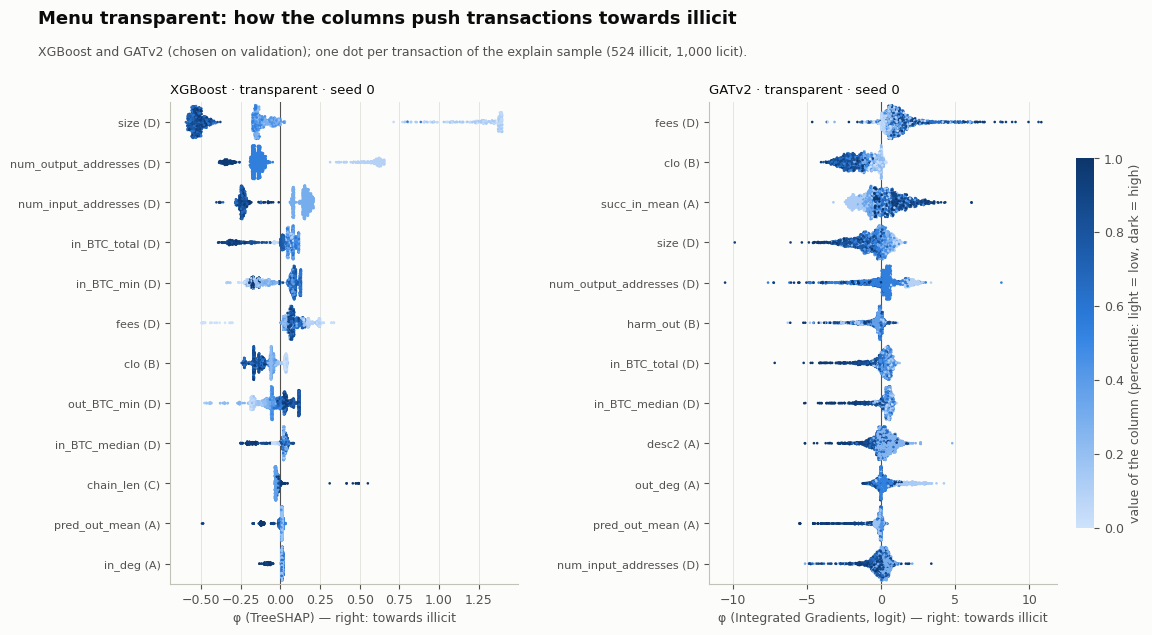

06_beeswarm_transparent.png written (153 KB).


In [9]:
def load_matrix(menu, model, seed=REFERENCE_SEED):
    path = OUT_DIR / 'shap' / f'{triple_id(menu, model, seed)}.parquet'
    if not path.exists():
        return None
    table = pd.read_parquet(path)
    return table[table['row'].isin(SAMPLE['row'])].reset_index(drop=True)   # the explain sample for every model


def swarm_offsets(x, width=0.42, bins=60):
    """Vertical offsets of a beeswarm: dots with close values are spread up and down in turn."""
    edges = np.linspace(x.min(), x.max() + 1e-12, bins + 1)
    b = np.clip(np.searchsorted(edges, x, side='right') - 1, 0, bins - 1)
    counts, seen, pos = np.bincount(b, minlength=bins), np.zeros(bins, dtype=int), np.zeros(len(x))
    for i in np.random.default_rng(0).permutation(len(x)):
        k = seen[b[i]]
        pos[i] = (k + 1) // 2 * (1 if k % 2 else -1)
        seen[b[i]] += 1
    return pos * width / max(counts.max() / 2, 1)


def beeswarm(ax, menu, model, top=SWARM_TOP):
    table = load_matrix(menu, model)
    if table is None or model is None:
        empty_panel(ax, f'{menu} · {MODEL_NAME.get(model, model)}: not available')
        return
    columns = config['menus'][menu]['columns']
    phi = table[columns].to_numpy()
    w = WEIGHT.loc[table['row']].to_numpy()
    order = np.argsort(-(w @ np.abs(phi)))[:top]
    for k, j in enumerate(order):
        x = phi[:, j]
        value = RAW[columns[j]].to_numpy()[table['row'].to_numpy()]
        rank = pd.Series(value).rank(pct=True).to_numpy()
        ax.scatter(x, k + swarm_offsets(x), c=BLUE_CMAP(np.nan_to_num(rank, nan=0.0)), s=3.5, linewidths=0, zorder=2)
    ax.set_yticks(range(len(order)), [f'{columns[j]} ({FAM[columns[j]]})' for j in order], fontsize=8)
    ax.set_ylim(len(order) - 0.5, -0.5)
    ax.axvline(0, color=INK_2, linewidth=0.8, zorder=1)
    ax.set_xlabel(f'φ ({ATTR_LABEL[ATTR_METHOD[model]]}) — right: towards illicit')
    ax.set_title(f'{MODEL_NAME[model]} · {menu} · seed {REFERENCE_SEED}', fontsize=9.5, loc='left')
    light_grid(ax, 'x')


def beeswarm_figure(menu, gnn, name, how='chosen on validation'):
    fig, axes = plt.subplots(1, 2, figsize=(12, 6.6))
    fig.subplots_adjust(left=0.13, right=0.9, top=0.83, bottom=0.1, wspace=0.55)
    beeswarm(axes[0], menu, 'xgb')
    beeswarm(axes[1], menu, gnn)
    bar = fig.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap=BLUE_CMAP), ax=axes, fraction=0.02, pad=0.02)
    bar.set_label('value of the column (percentile: light = low, dark = high)', color=INK_2)
    bar.outline.set_visible(False)
    titles(fig, f'Menu {menu}: how the columns push transactions towards illicit',
           f'XGBoost and {MODEL_NAME.get(gnn, "the GNN")} ({how}); one dot per transaction of the '
           'explain sample (524 illicit, 1,000 licit).')
    save_png(fig, name)


beeswarm_figure('transparent', CHOSEN['transparent'], '06_beeswarm_transparent.png')

## 6. Plot 4 — the shape of the effect (`06_dependence.png`)

The 4 columns with the largest mean $|\phi|$ of XGBoost on `transparent`: the value of the column (horizontal; logarithmic when its values span several orders of magnitude) against its $\phi$, for XGBoost (top) and the GNN chosen on validation (bottom), on the explain sample, seed 0. Dots coloured by class. A step shows a threshold; a slope a gradual effect.

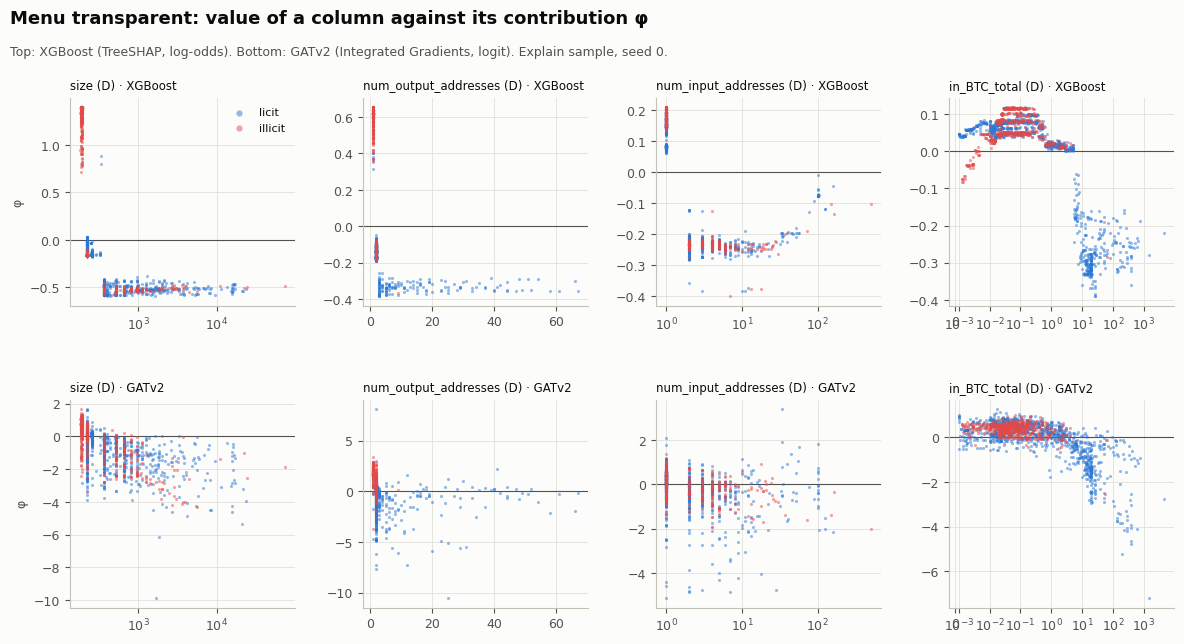

06_dependence.png written (133 KB).


In [10]:
xgb_table = load_matrix('transparent', 'xgb')
gnn = CHOSEN['transparent']
gnn_table = load_matrix('transparent', gnn) if gnn else None
fig, axes = plt.subplots(2, 4, figsize=(12, 6.8))
fig.subplots_adjust(left=0.07, right=0.99, top=0.84, bottom=0.09, wspace=0.3, hspace=0.45)
if xgb_table is not None:
    columns = config['menus']['transparent']['columns']
    w = WEIGHT.loc[xgb_table['row']].to_numpy()
    top = [columns[j] for j in np.argsort(-(w @ np.abs(xgb_table[columns].to_numpy())))[:4]]
    for row, (model, table) in enumerate([('xgb', xgb_table), (gnn, gnn_table)]):
        for col, column in enumerate(top):
            ax = axes[row, col]
            if table is None:
                empty_panel(ax, 'not available')
                continue
            value = RAW[column].to_numpy()[table['row'].to_numpy()]
            for cls, name in [(0, 'licit'), (1, 'illicit')]:
                sel = table['y'].to_numpy() == cls
                ax.scatter(value[sel], table[column].to_numpy()[sel], s=5, color=CLASS_COLOR[name], alpha=0.5,
                           linewidths=0, label=name, zorder=2)
            positive = np.abs(value[np.isfinite(value) & (value != 0)])
            if len(positive) and np.nanpercentile(np.abs(value), 99) > 20 * max(np.nanpercentile(np.abs(value), 50), 1e-9):
                ax.set_xscale('symlog', linthresh=float(np.percentile(positive, 10)))
            ax.axhline(0, color=INK_2, linewidth=0.8, zorder=1)
            ax.set_title(f'{column} ({FAM[column]}) · {MODEL_NAME[model]}', fontsize=8.5, loc='left')
            if col == 0:
                ax.set_ylabel('φ')
            light_grid(ax, 'both')
    axes[0, 0].legend(frameon=False, fontsize=8, markerscale=2)
else:
    for ax in axes.flat:
        empty_panel(ax, 'not available')
titles(fig, 'Menu transparent: value of a column against its contribution φ',
       f'Top: XGBoost (TreeSHAP, log-odds). Bottom: {MODEL_NAME.get(gnn, "GNN")} (Integrated Gradients, logit). '
       f'Explain sample, seed {REFERENCE_SEED}.')
save_png(fig, '06_dependence.png')

## 7. Plot 5 — the drop when a family is removed, with its spread (`06_family_drop.png`)

Menu `local_agg_graph`: one panel per family, one row per model. The dot is the drop of test PR-AUC when the family is shuffled (mean over the 3 seeds), the line its standard deviation over the seeds. It is the question of the menus (step 05) seen inside one model: step 05 retrains without a group, here the trained model loses it.

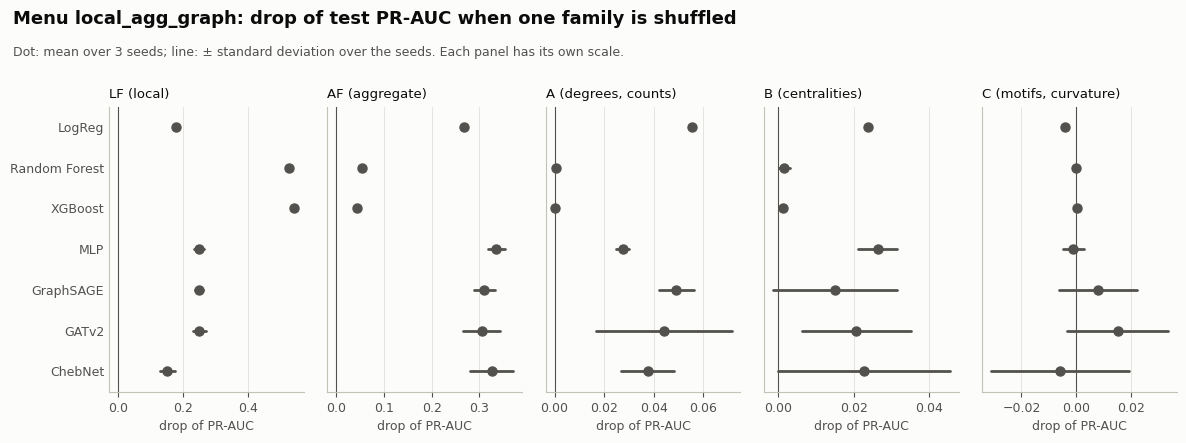

06_family_drop.png written (47 KB).


In [11]:
menu = 'local_agg_graph'
families = [f for f in FAMILIES if any(FAM[c] == f for c in config['menus'][menu]['columns'])]
models = [m for m in MODELS if (menu, m) in PAIR_SET]
fig, axes = plt.subplots(1, len(families), figsize=(12, 4.6), sharey=True)
fig.subplots_adjust(left=0.1, right=0.99, top=0.76, bottom=0.14, wspace=0.12)
for ax, f in zip(axes, families):
    for k, model in enumerate(models):
        mean = summary(menu, model, 'permutation', 'ap_drop', level='family', data='test')
        std = summary(menu, model, 'permutation', 'ap_drop', level='family', data='test', stat='std')
        if f in mean.index:
            s = 0 if not np.isfinite(std.get(f, np.nan)) else std[f]
            ax.plot([mean[f] - s, mean[f] + s], [k, k], color=NEUTRAL, linewidth=2, solid_capstyle='round', zorder=2)
            ax.plot(mean[f], k, 'o', color=NEUTRAL, markersize=6.5, zorder=3)
    ax.axvline(0, color=INK_2, linewidth=0.8)
    ax.set_title(FAMILY_NAME[f], fontsize=9.5, loc='left')
    ax.set_xlabel('drop of PR-AUC')
    light_grid(ax, 'x')
    ax.tick_params(axis='y', length=0)
axes[0].set_yticks(range(len(models)), [MODEL_NAME[m] for m in models])
axes[0].set_ylim(len(models) - 0.5, -0.5)
titles(fig, 'Menu local_agg_graph: drop of test PR-AUC when one family is shuffled',
       'Dot: mean over 3 seeds; line: ± standard deviation over the seeds. Each panel has its own scale.')
for ax in axes:
    ax.set_xlim(left=min(ax.get_xlim()[0], -0.002))
save_png(fig, '06_family_drop.png')

## 8. Plot 6 — are the explanations robust? (`06_stability.png`)

Spearman correlation between rankings of the columns (1 = same order):
- **between seeds**: the same model trained with another seed, permutation importance (mean over the 3 pairs of seeds);
- **between methods**: permutation importance against the attributions (SHAP or Integrated Gradients), means over the seeds;
- **between models** on `transparent`: permutation importance of two models.

The overlap of the top columns is in `stability.csv`.

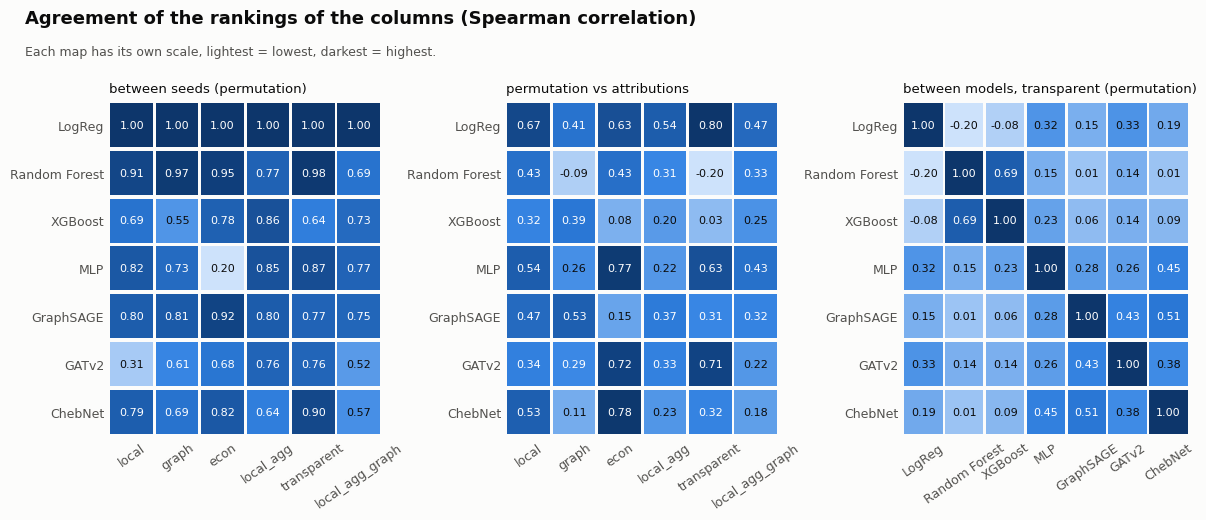

06_stability.png written (116 KB).


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5.4), gridspec_kw={'width_ratios': [1, 1, 1.05]})
fig.subplots_adjust(left=0.09, right=0.99, top=0.8, bottom=0.18, wspace=0.45)
norm = Normalize(-1, 1)
for ax, (kind, method, title) in zip(axes[:2], [('between seeds', 'permutation', 'between seeds (permutation)'),
                                                 ('between methods', 'permutation', 'permutation vs attributions')]):
    models = [m for m in MODELS if m != 'gin']
    values = np.full((len(models), len(FEATURE_MENUS)), np.nan)
    for i, model in enumerate(models):
        for j, menu in enumerate(FEATURE_MENUS):
            sel = STABILITY[(STABILITY['kind'] == kind) & (STABILITY['method'] == method) & (STABILITY['model'] == model)
                            & (STABILITY['menu'] == menu)] if len(STABILITY) else []
            if len(sel):
                values[i, j] = sel['spearman'].iloc[0]
    texts = [[f'{v:.2f}' if np.isfinite(v) else '' for v in row] for row in values]
    if np.isfinite(values).any():
        heatmap(ax, values, [MODEL_NAME[m] for m in models], FEATURE_MENUS, texts)
        ax.tick_params(axis='x', labelrotation=35)
    else:
        empty_panel(ax, 'not available')
    ax.set_title(title, fontsize=9.5, loc='left')
models = [m for m in MODELS if ('transparent', m) in PAIR_SET]
values = np.full((len(models), len(models)), np.nan)
for i, a in enumerate(models):
    values[i, i] = 1.0
    for j, b in enumerate(models):
        sel = STABILITY[(STABILITY['kind'] == 'between models') & (STABILITY['menu'] == 'transparent')
                        & (((STABILITY['model'] == a) & (STABILITY['with'] == b)) |
                           ((STABILITY['model'] == b) & (STABILITY['with'] == a)))] if len(STABILITY) else []
        if len(sel):
            values[i, j] = sel['spearman'].iloc[0]
texts = [[f'{v:.2f}' if np.isfinite(v) else '' for v in row] for row in values]
heatmap(axes[2], values, [MODEL_NAME[m] for m in models], [MODEL_NAME[m] for m in models], texts)
axes[2].tick_params(axis='x', labelrotation=35)
axes[2].set_title('between models, transparent (permutation)', fontsize=9.5, loc='left')
titles(fig, 'Agreement of the rankings of the columns (Spearman correlation)',
       'Each map has its own scale, lightest = lowest, darkest = highest.')
save_png(fig, '06_stability.png')

## 9. Plot 7 — what a GNN looks at: examples (`06_gnnexplainer_examples.png`)

The GNN chosen on validation for `transparent`, seed 0. Three nodes of the GNNExplainer core, chosen by a fixed rule (among the nodes whose neighbourhood within 2 hops has 5 to 60 nodes, so that it can be drawn): the two illicit transactions **found** (TP) with the highest score and the illicit transaction **missed** (FN) with the highest score. The neighbourhood within 2 hops: node colour = class, the explained node with a black ring; edge width and darkness = GNNExplainer mask (how much the GNN needs that edge).

/tmp/ipykernel_1640/3039097919.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sizes = edges.groupby('target_row').apply(lambda g: len(set(g['src_row']) | set(g['dst_row'])))


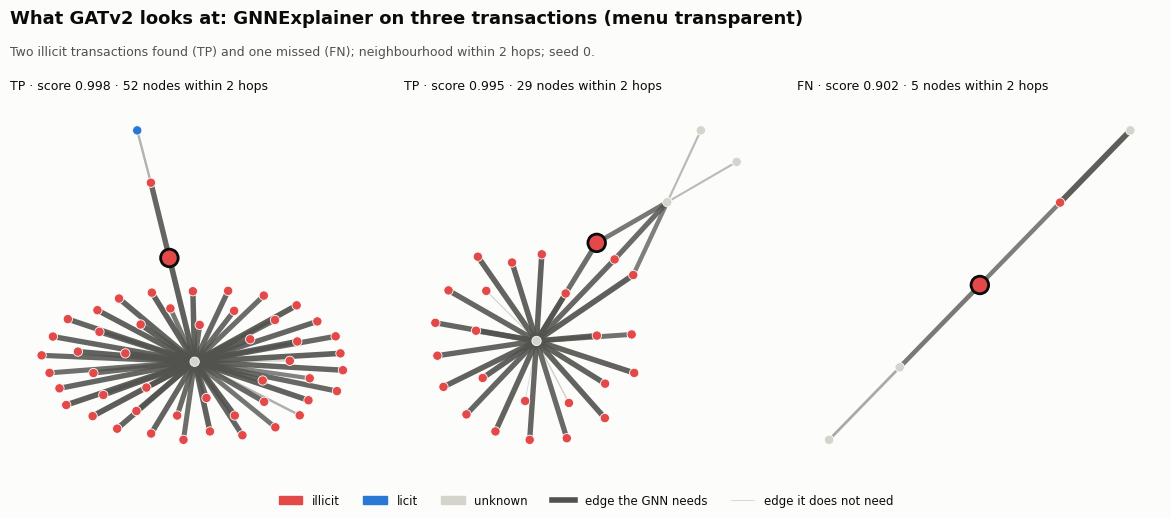

06_gnnexplainer_examples.png written (119 KB).


In [13]:
def example_nodes(pair, model, menu):
    edges = pd.read_parquet(OUT_DIR / 'gnnexplainer' / f'{pair}__edges.parquet')
    edges = edges[edges['core']]
    saved = pd.read_parquet(RUNS_DIR / 'predictions' / f'{triple_id(menu, model, REFERENCE_SEED)}.parquet')
    score = saved[saved['split'] == 'test'].set_index('row')['score']
    sizes = edges.groupby('target_row').apply(lambda g: len(set(g['src_row']) | set(g['dst_row'])))
    info = edges.groupby('target_row')['stratum'].first().to_frame('stratum')
    info['nodes'], info['score'] = sizes, score.reindex(info.index)
    ok = info[(info['nodes'] >= 5) & (info['nodes'] <= 60)].sort_values('score', ascending=False)
    picks = list(ok[ok['stratum'] == 'TP'].index[:2]) + list(ok[ok['stratum'] == 'FN'].index[:1])
    return edges, info, picks


def draw_neighbourhood(ax, edges, target, info):
    sub = edges[edges['target_row'] == target]
    g = nx.Graph()
    for r in sub.itertuples():
        weight = max(r.mask, g[r.src_row][r.dst_row]['mask']) if g.has_edge(r.src_row, r.dst_row) else r.mask
        g.add_edge(r.src_row, r.dst_row, mask=weight)
    pos = nx.spring_layout(g, seed=0)
    masks = np.array([g[u][v]['mask'] for u, v in g.edges()])
    nx.draw_networkx_edges(g, pos, ax=ax, width=0.4 + 4 * masks,
                           edge_color=[(0.32, 0.32, 0.31, 0.15 + 0.85 * m) for m in masks])
    nodes = list(g.nodes())
    colors = [CLASS_COLOR[CLASS_NAMES[CLASS_OF[n]]] for n in nodes]
    sizes = [160 if n == target else 45 for n in nodes]
    nx.draw_networkx_nodes(g, pos, ax=ax, nodelist=nodes, node_color=colors, node_size=sizes,
                           edgecolors=[INK if n == target else SURFACE for n in nodes],
                           linewidths=[2 if n == target else 0.6 for n in nodes])
    ax.set_title(f"{info.loc[target, 'stratum']} · score {info.loc[target, 'score']:.3f} · "
                 f"{int(info.loc[target, 'nodes'])} nodes within 2 hops", fontsize=9, loc='left')
    ax.axis('off')


gnn = CHOSEN['transparent']
fig, axes = plt.subplots(1, 3, figsize=(12, 5.2))
fig.subplots_adjust(left=0.02, right=0.98, top=0.8, bottom=0.08, wspace=0.08)
pair = f'transparent__{gnn}'
if gnn and (OUT_DIR / 'gnnexplainer' / f'{pair}__edges.parquet').exists():
    edges, info, picks = example_nodes(pair, gnn, 'transparent')
    for ax, target in zip(axes, picks):
        draw_neighbourhood(ax, edges, target, info)
    for ax in axes[len(picks):]:
        empty_panel(ax, 'no node fits the rule')
else:
    for ax in axes:
        empty_panel(ax, 'not available')
fig.legend(handles=[Patch(color=CLASS_COLOR[c], label=c) for c in CLASS_NAMES] +
           [Line2D([], [], color=NEUTRAL, linewidth=4, label='edge the GNN needs'),
            Line2D([], [], color=NEUTRAL, linewidth=0.5, alpha=0.3, label='edge it does not need')],
           loc='lower center', ncol=5, frameon=False, fontsize=8.5)
titles(fig, f'What {MODEL_NAME.get(gnn, "the GNN")} looks at: GNNExplainer on three transactions (menu transparent)',
       'Two illicit transactions found (TP) and one missed (FN); neighbourhood within 2 hops; '
       f'seed {REFERENCE_SEED}.')
save_png(fig, '06_gnnexplainer_examples.png')

## 10. Plot 8 — which neighbours matter, by stratum (`06_edges_by_neighbour.png`)

All 20 (menu, GNN) pairs together, seed 0. For each stratum of explained nodes (TP: illicit found; FN: illicit missed; FP: licit flagged by mistake; TN: licit correctly ignored), the mean GNNExplainer mask of the edges by distance from the node (1, 2, 3 or more hops) and class of the neighbour at the far end of the edge. For each node the mean over its edges, then the mean over the nodes of a pair, then over the pairs. Step 00 found that 60% of the neighbours of illicit transactions are unknown, but among the labelled ones 54% are illicit: do the GNNs use the illicit neighbours more?

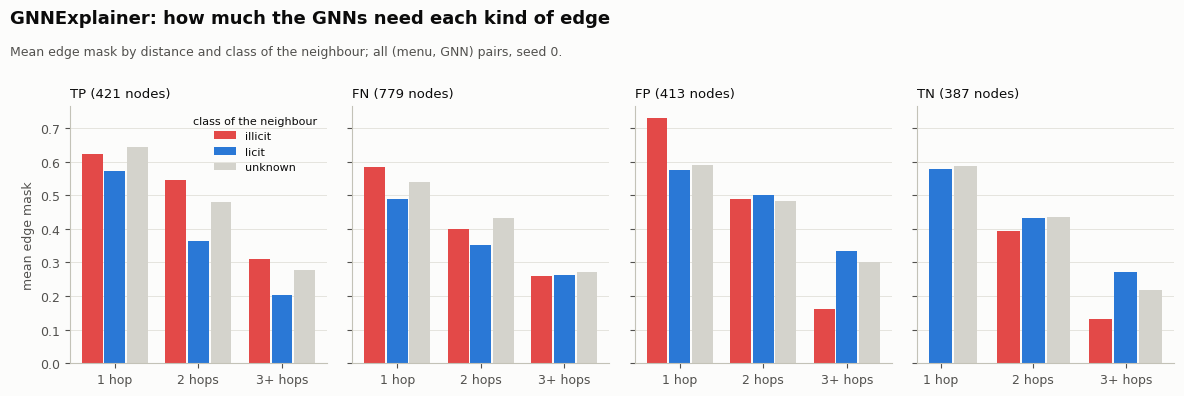

06_edges_by_neighbour.png written (40 KB).


In [14]:
fig, axes = plt.subplots(1, 4, figsize=(12, 4.6), sharey=True)
fig.subplots_adjust(left=0.07, right=0.99, top=0.76, bottom=0.2, wspace=0.1)
buckets = ['1', '2', '3+']
if len(BY_DISTANCE):
    pooled = GX_SUMMARY.groupby(['stratum', 'bucket', 'neighbour_class'])['mean_mask'].mean()
    nodes = per_node.groupby(['pair', 'stratum'])['target_row'].nunique().groupby('stratum').sum()
    for ax, stratum in zip(axes, STRATA):
        for c, cls in enumerate(CLASS_NAMES):
            values = [pooled.get((stratum, b, cls), np.nan) for b in buckets]
            ax.bar(np.arange(3) + (c - 1) * 0.27, values, 0.25, color=CLASS_COLOR[cls], zorder=2, label=cls)
        ax.set_xticks(range(3), [f'{b} hop' + ('s' if b != '1' else '') for b in buckets])
        ax.set_title(f'{stratum} ({int(nodes.get(stratum, 0))} nodes)', fontsize=9.5, loc='left')
        light_grid(ax)
    axes[0].set_ylabel('mean edge mask')
    axes[0].legend(title='class of the neighbour', frameon=False, fontsize=8, title_fontsize=8, loc='upper right')
else:
    for ax in axes:
        empty_panel(ax, 'not available')
titles(fig, 'GNNExplainer: how much the GNNs need each kind of edge',
       'Mean edge mask by distance and class of the neighbour; all (menu, GNN) pairs, seed 0.')
save_png(fig, '06_edges_by_neighbour.png')

## 11. Plot 9 — internal importances of step 04 against attributions (`06_internal_vs_shap.png`)

Step 04 saved the importances that each library computes by itself: the coefficient of the Logistic Regression (on z-scored inputs), the mean decrease in impurity of the Random Forest, the gain of XGBoost. They are cheap but each has its own definition (the impurity and the gain can favour columns with many distinct values). Left: XGBoost on `transparent`, seed 0, gain against mean $|\phi|$ of TreeSHAP for every column (logarithmic axes; the 5 columns with the largest $|\phi|$ are named). Right: Spearman correlation between the internal ranking and the attribution ranking, for every menu, mean over the seeds.

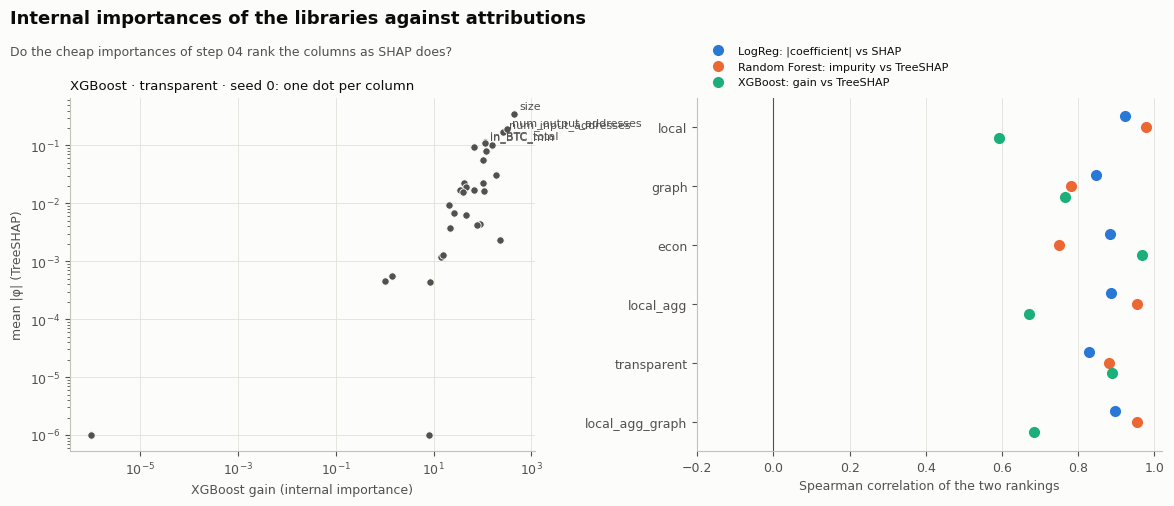

06_internal_vs_shap.png written (71 KB).


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
fig.subplots_adjust(left=0.07, right=0.98, top=0.8, bottom=0.12, wspace=0.35)
ax = axes[0]
gain = per_seed('transparent', 'xgb', 'internal', 'abs').get(REFERENCE_SEED)
shap_mean = per_seed('transparent', 'xgb', 'tree_shap', 'mean_abs').get(REFERENCE_SEED)
if gain is not None and shap_mean is not None:
    common = gain.index.intersection(shap_mean.index)
    x, y = gain[common].clip(lower=1e-6), shap_mean[common].clip(lower=1e-6)
    ax.scatter(x, y, s=28, color=NEUTRAL, edgecolor=SURFACE, linewidth=0.6, zorder=2)
    for name in y.sort_values(ascending=False).index[:5]:
        ax.annotate(name, (x[name], y[name]), xytext=(4, 3), textcoords='offset points', fontsize=8, color=INK_2)
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('XGBoost gain (internal importance)')
    ax.set_ylabel('mean |φ| (TreeSHAP)')
    ax.set_title(f'XGBoost · transparent · seed {REFERENCE_SEED}: one dot per column', fontsize=9.5, loc='left')
    light_grid(ax, 'both')
else:
    empty_panel(ax, 'not available')
ax = axes[1]
for k, model in enumerate(['logreg', 'rf', 'xgb']):
    rhos = []
    for menu in FEATURE_MENUS:
        a, b = summary(menu, model, 'internal', 'abs'), summary(menu, model, ATTR_METHOD[model], 'mean_abs')
        common = a.index.intersection(b.index)
        rhos.append(spearmanr(a[common], b[common]).correlation if len(common) > 2 else np.nan)
    ax.plot(rhos, np.arange(len(FEATURE_MENUS)) + (k - 1) * 0.18, 'o', color=SERIES[k], markersize=7,
            label=f"{MODEL_NAME[model]}: {['|coefficient|', 'impurity', 'gain'][k]} vs {ATTR_LABEL[ATTR_METHOD[model]].split(',')[0]}")
ax.set_yticks(range(len(FEATURE_MENUS)), FEATURE_MENUS)
ax.set_ylim(len(FEATURE_MENUS) - 0.5, -0.5)
ax.set_xlim(-0.2, 1.02)
ax.axvline(0, color=INK_2, linewidth=0.8)
ax.set_xlabel('Spearman correlation of the two rankings')
ax.legend(frameon=False, fontsize=8, loc='lower left', bbox_to_anchor=(0, 1.0))
light_grid(ax, 'x')
titles(fig, 'Internal importances of the libraries against attributions',
       'Do the cheap importances of step 04 rank the columns as SHAP does?')
save_png(fig, '06_internal_vs_shap.png')

## 12. Plot 10 — one transaction, explained (`06_waterfall.png`)

XGBoost on `transparent`, seed 0, one illicit transaction found by the model, chosen by a fixed rule: among the illicit transactions of the explain sample flagged at the threshold chosen on validation, the one with the **median** score. Starting from the base value (the mean output of the model), every column adds or removes a piece (red: towards "illicit", blue: towards "licit"), up to the output of the model for this transaction. The 10 largest pieces are shown; the others are summed in one bar. Log-odds; the probability is $1/(1+e^{-\text{log-odds}})$.

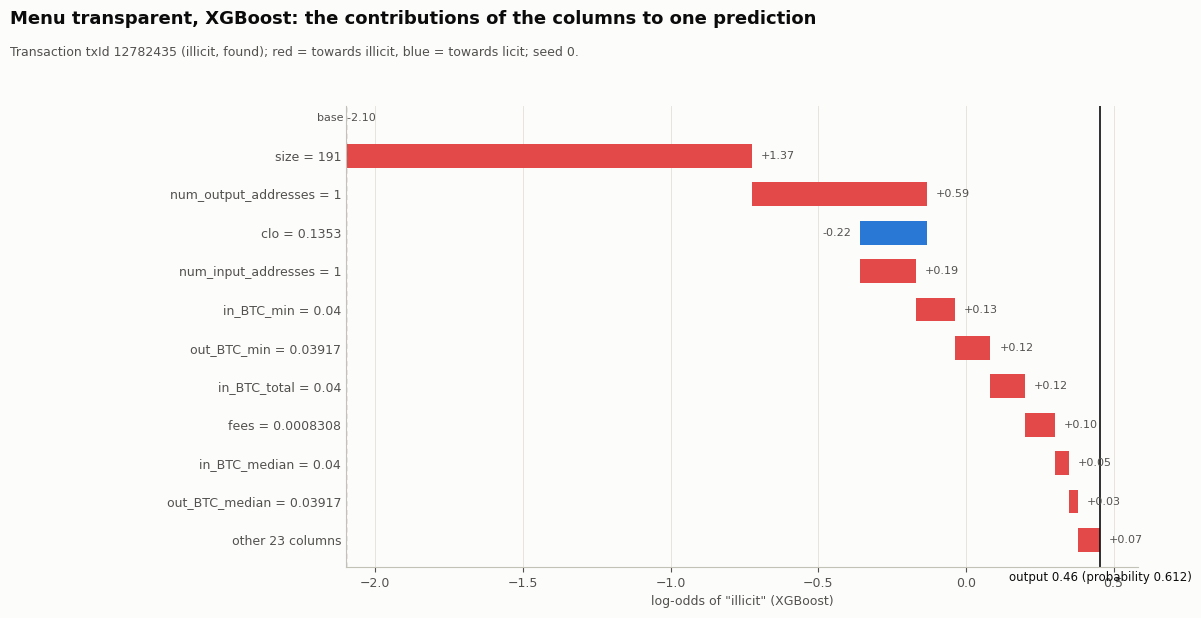

06_waterfall.png written (60 KB).


In [16]:
table = load_matrix('transparent', 'xgb')
fig, ax = plt.subplots(figsize=(12, 6.4))
fig.subplots_adjust(left=0.3, right=0.96, top=0.82, bottom=0.1)
if table is not None:
    record = RECORDS[('transparent', 'xgb', REFERENCE_SEED)]
    threshold = record['metrics']['thresholds']['best_val_f1']
    probability = 1 / (1 + np.exp(-table['output'].to_numpy()))
    found = table[(table['y'] == 1) & (probability >= threshold)].copy()
    if not len(found):   # no illicit transaction flagged: take every illicit one
        found = table[table['y'] == 1].copy()
    found['p'] = 1 / (1 + np.exp(-found['output']))
    found = found.sort_values('p', kind='stable')
    pick = found.iloc[len(found) // 2]
    columns = config['menus']['transparent']['columns']
    phi = pick[columns].astype(float)
    top = phi.abs().sort_values(ascending=False).index[:10]
    rest = phi.drop(top).sum()
    steps = [(f'{c} = {RAW[c].iloc[int(pick["row"])]:.4g}', phi[c]) for c in top]
    steps.append((f'other {len(columns) - len(top)} columns', rest))
    position = pick['base']
    for k, (label, value) in enumerate(steps):
        color = CLASS_COLOR['illicit'] if value > 0 else CLASS_COLOR['licit']
        ax.barh(k, value, left=position, height=0.62, color=color, zorder=2)
        ax.text(position + value + (0.03 if value > 0 else -0.03), k, f'{value:+.2f}', va='center',
                ha='left' if value > 0 else 'right', fontsize=8, color=INK_2)
        position += value
    ax.axvline(pick['base'], color=INK_2, linewidth=0.9, linestyle=(0, (4, 3)))
    ax.axvline(position, color=INK, linewidth=1.2)
    ax.text(pick['base'], -0.9, f"base {pick['base']:.2f}", ha='center', fontsize=8, color=INK_2)
    ax.text(position, len(steps) - 0.2, f"output {position:.2f} (probability {1 / (1 + np.exp(-position)):.3f})",
            ha='center', va='top', fontsize=8.5, color=INK)
    ax.set_yticks(range(len(steps)), [s[0] for s in steps])
    ax.set_ylim(len(steps) - 0.3, -1.3)
    ax.set_xlabel('log-odds of "illicit" (XGBoost)')
    light_grid(ax, 'x')
    ax.tick_params(axis='y', length=0)
    subtitle = (f"Transaction txId {int(SAMPLE.set_index('row').loc[int(pick['row']), 'txId'])} (illicit, found); "
                f"red = towards illicit, blue = towards licit; seed {REFERENCE_SEED}.")
else:
    empty_panel(ax, 'not available')
    subtitle = ''
titles(fig, 'Menu transparent, XGBoost: the contributions of the columns to one prediction', subtitle)
save_png(fig, '06_waterfall.png')

## 13. Plot 11 — own features or neighbours? (`06_self_vs_neighbours.png`)

For every GNN and menu: the **share of the attribution** (Integrated Gradients) **that comes from the features of the neighbours**, for every family of the menu and for the whole menu (row "all"), mean over the seeds. 0 = the GNN uses only the features of the transaction itself, as an MLP (whose share is 0 by construction); 1 = only those of its neighbours. It links to "GNN − MLP" of step 05: a GNN that beats its MLP should also draw a good part of its attribution from the neighbours. Each map has its own scale, lightest = lowest, darkest = highest.

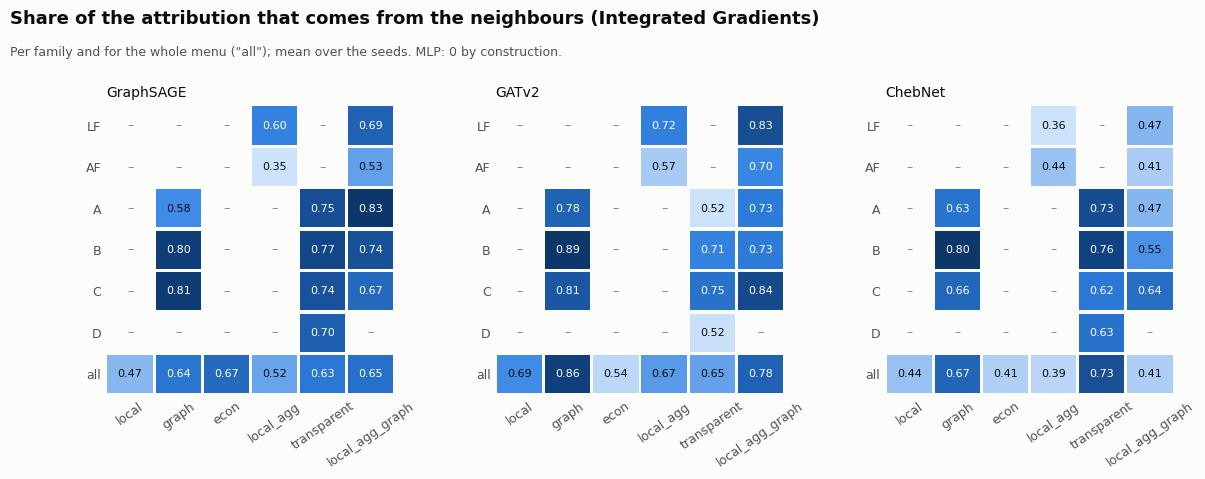

06_self_vs_neighbours.png written (69 KB).


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))
fig.subplots_adjust(left=0.1, right=0.99, top=0.78, bottom=0.2, wspace=0.35)
rows_labels = FAMILIES + ['all']
for ax, gnn in zip(axes, GNNS):
    values = np.full((len(rows_labels), len(FEATURE_MENUS)), np.nan)
    for j, menu in enumerate(FEATURE_MENUS):
        fam = summary(menu, gnn, 'integrated_gradients', 'neighbour_share', level='family')
        whole = summary(menu, gnn, 'integrated_gradients', 'neighbour_share', level='menu')
        for i, f in enumerate(FAMILIES):
            if f in fam.index:
                values[i, j] = fam[f]
        if 'all' in whole.index:
            values[-1, j] = whole['all']
    texts = [[f'{v:.2f}' if np.isfinite(v) else '' for v in row] for row in values]
    if np.isfinite(values).any():
        heatmap(ax, values, rows_labels, FEATURE_MENUS, texts)
        ax.tick_params(axis='x', labelrotation=35)
    else:
        empty_panel(ax, 'not available')
    ax.set_title(MODEL_NAME[gnn], fontsize=10, loc='left')
titles(fig, 'Share of the attribution that comes from the neighbours (Integrated Gradients)',
       'Per family and for the whole menu ("all"); mean over the seeds. MLP: 0 by construction.')
save_png(fig, '06_self_vs_neighbours.png')

## 14. Plot 12 — test against validation (`06_test_vs_validation.png`)

The permutation of the families was also done on the validation (time steps 31–40). For each menu with two families or more and each family: the drop of PR-AUC on validation and on the test, mean over the models and seeds. If the two dots are far apart, what the models rely on changes from one period to the other (the prevalence of illicit halves in the test).

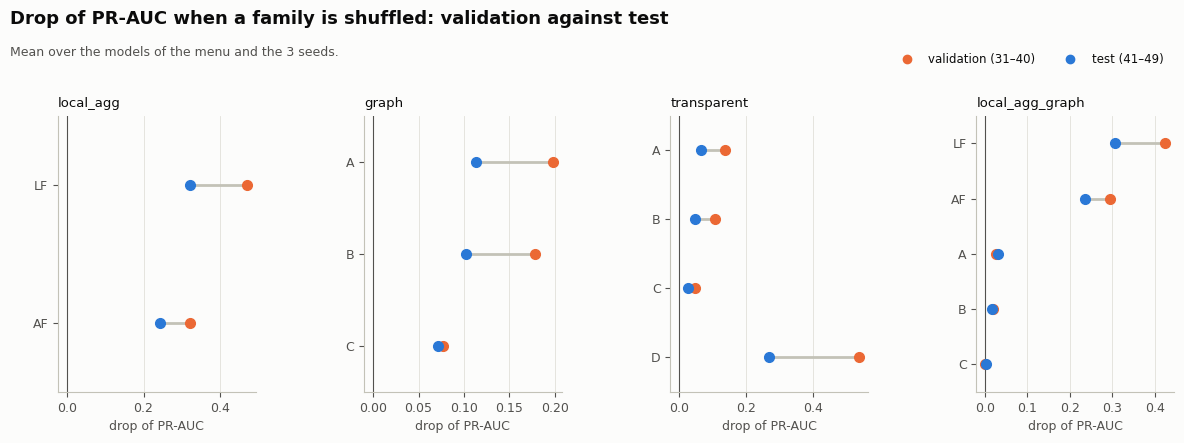

06_test_vs_validation.png written (41 KB).


In [18]:
fig, axes = plt.subplots(1, 4, figsize=(12, 4.6))
fig.subplots_adjust(left=0.06, right=0.99, top=0.74, bottom=0.14, wspace=0.55)
fam_rows = SUMMARY[(SUMMARY['method'] == 'permutation') & (SUMMARY['level'] == 'family') & (SUMMARY['measure'] == 'ap_drop')]
for ax, menu in zip(axes, MULTI_FAMILY):
    sel = fam_rows[fam_rows['menu'] == menu].groupby(['name', 'data'])['mean'].mean().unstack()
    families = [f for f in FAMILIES if f in sel.index]
    if not families or not {'test', 'val'} <= set(sel.columns):
        empty_panel(ax, f'{menu}: not available')
        continue
    for k, f in enumerate(families):
        ax.plot([sel.loc[f, 'val'], sel.loc[f, 'test']], [k, k], color=AXIS, linewidth=2, zorder=1)
        ax.plot(sel.loc[f, 'val'], k, 'o', color=SERIES[1], markersize=7, zorder=2)
        ax.plot(sel.loc[f, 'test'], k, 'o', color=SERIES[0], markersize=7, zorder=3)
    ax.set_yticks(range(len(families)), families)
    ax.set_ylim(len(families) - 0.5, -0.5)
    ax.axvline(0, color=INK_2, linewidth=0.8)
    ax.set_title(menu, fontsize=9.5, loc='left')
    ax.set_xlabel('drop of PR-AUC')
    light_grid(ax, 'x')
fig.legend(handles=[Line2D([], [], marker='o', linestyle='', color=SERIES[1], label='validation (31–40)'),
                    Line2D([], [], marker='o', linestyle='', color=SERIES[0], label='test (41–49)')],
           loc='upper right', bbox_to_anchor=(0.99, 0.9), ncol=2, frameon=False, fontsize=8.5)
titles(fig, 'Drop of PR-AUC when a family is shuffled: validation against test',
       'Mean over the models of the menu and the 3 seeds.')
save_png(fig, '06_test_vs_validation.png')

## 15. Appendix — beeswarms of `econ` and `graph`, and the best GNN on the test

The same plot as section 5 for the menus `econ` (D only) and `graph` (A, B, C), with XGBoost and the GNN chosen on validation for that menu. If on `transparent` the best GNN on the test is not the one chosen on validation, its beeswarm is drawn too.

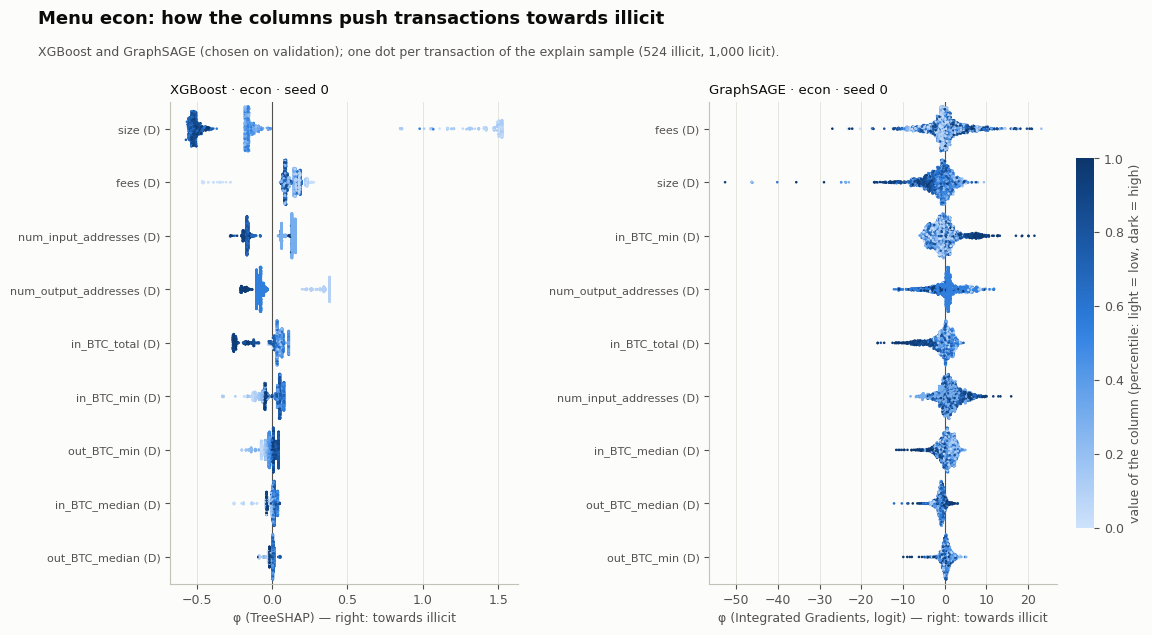

06_beeswarm_econ.png written (129 KB).


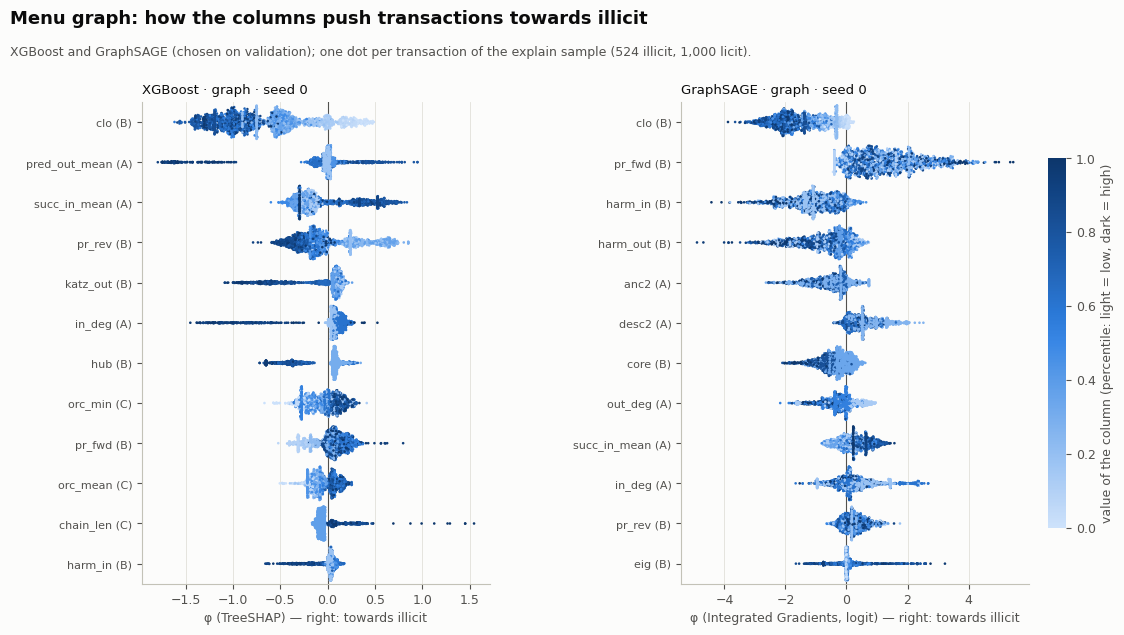

06_beeswarm_graph.png written (181 KB).
On transparent the best GNN on the test is ChebNet, not GATv2 (chosen on validation): its beeswarm goes to the appendix.


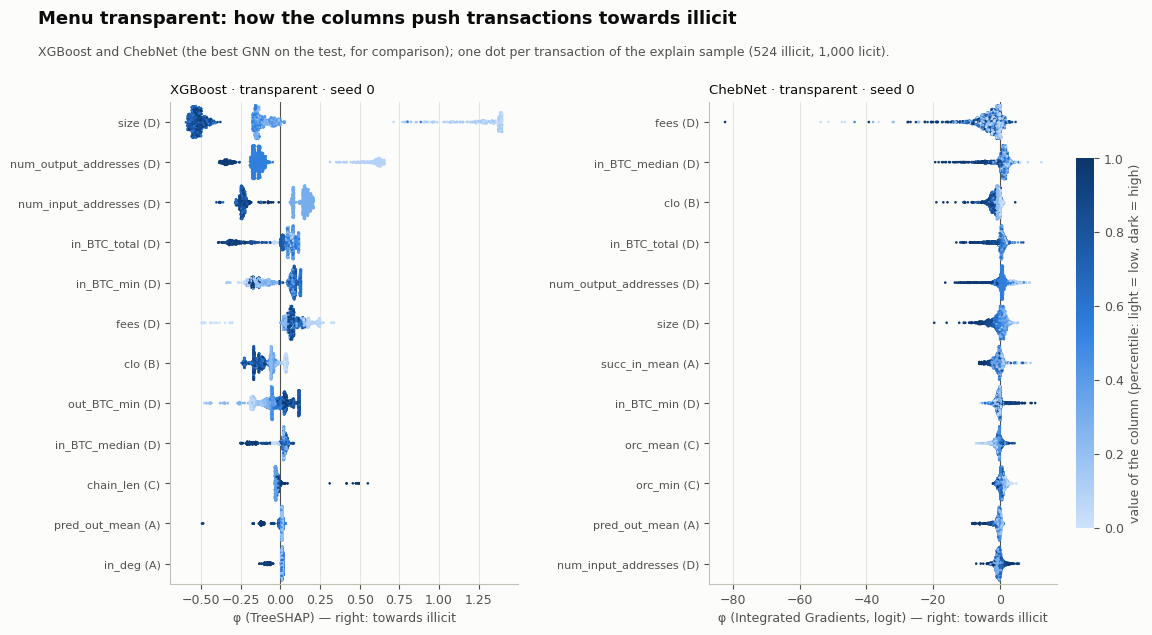

06_beeswarm_transparent_test_best.png written (136 KB).


In [19]:
beeswarm_figure('econ', CHOSEN['econ'], '06_beeswarm_econ.png')
beeswarm_figure('graph', CHOSEN['graph'], '06_beeswarm_graph.png')
if TEST_BEST['transparent'] and TEST_BEST['transparent'] != CHOSEN['transparent']:
    print(f"On transparent the best GNN on the test is {MODEL_NAME[TEST_BEST['transparent']]}, "
          f"not {MODEL_NAME[CHOSEN['transparent']]} (chosen on validation): its beeswarm goes to the appendix.")
    beeswarm_figure('transparent', TEST_BEST['transparent'], '06_beeswarm_transparent_test_best.png',
                    how='the best GNN on the test, for comparison')
else:
    print('On transparent the GNN chosen on validation is also the best on the test.')

In [20]:
for path in sorted(OUT_DIR.glob('*.csv')):
    print(f'{path.name:32s} {path.stat().st_size / 1e3:9.1f} KB')
for path in sorted(PLOT_DIR.glob('06_*.png')):
    print(f'{path.name:40s} {path.stat().st_size / 1e3:8.1f} KB')
drive.flush_and_unmount()

checks.csv                            35.2 KB
explain_sample.csv                    54.1 KB
gnnexplainer_features.csv            295.4 KB
gnnexplainer_stability.csv            60.1 KB
gnnexplainer_summary.csv              26.5 KB
importance.csv                     10939.9 KB
importance_summary.csv              4922.7 KB
stability.csv                         15.4 KB
06_beeswarm_econ.png                        128.7 KB
06_beeswarm_graph.png                       181.1 KB
06_beeswarm_transparent.png                 153.0 KB
06_beeswarm_transparent_test_best.png       135.9 KB
06_dependence.png                           132.6 KB
06_edges_by_neighbour.png                    39.8 KB
06_family_drop.png                           47.0 KB
06_family_heatmap.png                       116.5 KB
06_gnnexplainer_examples.png                119.3 KB
06_internal_vs_shap.png                      70.5 KB
06_self_vs_neighbours.png                    68.5 KB
06_stability.png                            115.9